# 07 · Confounding events and the sensitivity table
> Run after notebooks 01–03, from inside the `code` folder. Raw inputs are in `data/` (described in notebook 01). Research questions:
> top of notebook 03. All event-study calculations come from `buzzword_event_study.py`.

**Why this notebook?** A rename is often announced together with other news: a merger, a reverse merger, a SPAC
deal, a new business line, a reverse split. The stock then reacts to all of it, and the name gets the credit.
de Jong & Naumovska (2016) re-examined the famous dot-com study of Cooper, Dimitrov & Rau (2001): after
correcting dates and controlling for reverse mergers and restructurings, the "dot-com effect" was no longer
significant. McWilliams & Siegel (1997) and Kot (2011) make the same point for event studies and name changes in
general. Notebook 02 therefore coded the **deal type** of each event from the announcement that first names the
new name (a cosmetic, b pivot, c merger, d de-SPAC, e other news).

| Step | What happens |
|---|---|
| 0 | Settings and inputs (same as notebook 03) |
| 1 | CARs on the event dates (shared module) |
| 2 | **Results by deal type** (in-wave events with a grade A/B date) |
| 3 | **Sensitivity table** for the primary Dot-com and AI results: date grade, deal type, second-check rows, day-0 timing, effective dates, earliest recorded dates, benchmark, wave scope, influential events |
| 5 | **Peak-years check** of the wave windows (prevalence, reactions, control group) |
| 6 | **Threshold check** of our own event-study thresholds |
| 7 | **Dictionary audit** of the excluded ambiguous words |
| 8 | Figure and export |
| 9 | Overview figures |

All tests here are **exploratory**; the confirmatory tests are in notebook 03 (Step 11).

## Step 0: Settings and inputs

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import buzzword_event_study as es

np.random.seed(42)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rc("axes", titlesize=12, labelsize=11)

In [2]:
# ---- paths: run the notebooks from inside the code/ folder ----
base_dir = Path.cwd().parent                                  # project folder (the notebooks run from code/)
data_dir = base_dir / "data"                                  # raw input files (described in notebook 01)
wrds_dir = data_dir / "raw_data" / "wrds"
processed_dir = base_dir / "processed"
output_dir = base_dir / "output"

themes = ["Dot-com", "Blockchain", "AI"]
theme_colors = {"Dot-com": "#2a78b5", "Blockchain": "#e08a1e", "AI": "#3a9e5f"}
wave_periods = {"Dot-com": (1995, 2002), "Blockchain": (2016, 2020), "AI": (2021, 2025)}
deal_type_labels = {"a": "a cosmetic", "b": "b pivot", "c": "c merger / reverse merger", "d": "d de-SPAC",
                    "e": "e other news"}
deal_colors = {"a cosmetic": "#2a78b5", "b pivot": "#3a9e5f", "c merger / reverse merger": "#c0392b",
               "d de-SPAC": "#8e44ad", "e other news": "#7f7f7f"}
measures = [es.PRIMARY_MEASURE] + es.SECONDARY_MEASURES

dates = ["effective_date", "event_date", "public_announcement_date", "earliest_recorded_date"]
events = pd.read_csv(processed_dir / "events.csv", parse_dates=dates)
events["event_month"] = events["event_date"].dt.to_period("M").astype(str)
events["deal_label"] = events["deal_type"].map(deal_type_labels)
daily = es.load_daily(wrds_dir / "crsp_daily_event_firms.csv.gz")
market = es.load_market(wrds_dir / "crsp_daily_market_index.csv.gz")
pd.crosstab([events["theme"], events["in_wave_period"]], events["deal_label"])

deal_label                 a cosmetic  b pivot  c merger / reverse merger  d de-SPAC  e other news
theme      in_wave_period                                                                         
AI         1                        3        5                          1          5             0
Blockchain 0                        0        0                          1          1             0
           1                        0        2                          0          0             0
Dot-com    0                        7        3                          1          2             3
           1                       45        5                         13          0             0

## Step 1: CARs on the event dates

In [3]:
def event_cars(sample, model_name="market_model", date_column="event_date", shift_sessions=0):
    """
    Compute event-level CARs for one specification with the shared engine.

    Parameters
    ----------
    sample : pandas.DataFrame
        Events to include.
    model_name : str
        Benchmark (see :func:`es.compute_abnormal_returns`).
    date_column : str
        Date that defines day 0.
    shift_sessions : int
        Extra sessions added to day 0.

    Returns
    -------
    abnormal : pandas.DataFrame
    cars : pandas.DataFrame
        One row per usable event, with ``event_month``, ``deal_label`` and ``needs_second_check``.
    """
    abnormal, estimates, _ = es.compute_abnormal_returns(sample, daily, market, model_name, date_column,
                                                         timing_column="announcement_timing",
                                                         shift_sessions=shift_sessions)
    cars = es.compute_cars(abnormal, estimates, sample)
    extra = sample[["event_id", "deal_label", "needs_second_check"]].assign(
        event_month=sample[date_column].dt.to_period("M").astype(str))
    return abnormal, cars.merge(extra, on="event_id")


abnormal, cars = event_cars(events)
print("events with a complete CAR[-1,+1]:", int(cars[es.PRIMARY_MEASURE].notna().sum()), "of", len(events))

events with a complete CAR[-1,+1]: 94 of 97


## Step 2: Results by deal type
Sample: in-wave events with a grade A/B date. Dot-com and AI are shown separately and pooled; Blockchain events
are too few and are covered as case studies in notebook 03.

In [4]:
graded = cars[(cars["in_wave_period"] == 1) & cars["date_confidence"].isin(["A", "B"])]
rows = []
for theme in ["Dot-com", "AI", "Dot-com + AI"]:
    in_theme = graded["theme"].isin(["Dot-com", "AI"]) if theme == "Dot-com + AI" else graded["theme"] == theme
    for label in list(deal_type_labels.values()) + ["a + b (primary)", "c + d + e (confounded)"]:
        if label == "a + b (primary)":
            cell = graded[in_theme & graded["deal_type"].isin(["a", "b"])]
        elif label == "c + d + e (confounded)":
            cell = graded[in_theme & graded["deal_type"].isin(["c", "d", "e"])]
        else:
            cell = graded[in_theme & (graded["deal_label"] == label)]
        if cell.empty:
            continue
        for measure in measures:
            rows.append({"wave": theme, "deal_type": label, "measure": measure, **es.test_event_sample(cell, measure)})
by_deal_type = pd.DataFrame(rows)
by_deal_type[by_deal_type["measure"] == es.PRIMARY_MEASURE][
    ["wave", "deal_type", "n", "mean", "median", "pct_positive", "ci_low", "ci_high", "t_pvalue", "sign_pvalue",
     "boot_pvalue"]].round(4)

,wave,deal_type,n,mean,median,pct_positive,ci_low,ci_high,t_pvalue,sign_pvalue,boot_pvalue
0,Dot-com,a cosmetic,32,0.1049,0.0737,62.5000,0.0094,0.2005,0.0324,0.2153,0.0229
3,Dot-com,b pivot,5,-0.0288,0.0622,60.0000,-0.3490,0.2914,0.8151,1.0000,NaN
6,Dot-com,c merger / reverse merger,10,0.1265,0.0257,60.0000,-0.0479,0.3008,0.1353,0.7539,0.0847
9,Dot-com,a + b (primary),37,0.0869,0.0663,62.1622,-0.0014,0.1751,0.0534,0.1877,0.0447
12,Dot-com,c + d + e (confounded),10,0.1265,0.0257,60.0000,-0.0479,0.3008,0.1353,0.7539,0.0817
15,AI,a cosmetic,3,-0.0076,0.0139,66.6667,-0.1522,0.1370,0.8423,1.0000,NaN
18,AI,b pivot,5,0.0723,0.0644,60.0000,-0.2381,0.3827,0.5531,1.0000,NaN
21,AI,c merger / reverse merger,1,0.3281,0.3281,100.0000,NaN,NaN,NaN,NaN,NaN
24,AI,d de-SPAC,5,0.0669,0.0003,60.0000,-0.1258,0.2595,0.3899,1.0000,NaN
27,AI,a + b (primary),8,0.0423,0.0254,62.5000,-0.1215,0.2061,0.5604,0.7266,NaN


In [5]:
# Secondary window CAR[-5,+5] by deal type
by_deal_type[by_deal_type["measure"] == "car_m5_p5"][["wave", "deal_type", "n", "mean", "median", "t_pvalue",
                                                      "boot_pvalue"]].round(4)

,wave,deal_type,n,mean,median,t_pvalue,boot_pvalue
1,Dot-com,a cosmetic,32,0.1547,0.0351,0.0185,0.0105
4,Dot-com,b pivot,5,0.2377,0.2015,0.0525,NaN
7,Dot-com,c merger / reverse merger,10,0.0716,0.0160,0.4676,0.4301
10,Dot-com,a + b (primary),37,0.1659,0.0366,0.0046,0.0027
13,Dot-com,c + d + e (confounded),10,0.0716,0.0160,0.4676,0.4281
16,AI,a cosmetic,3,0.1057,0.1013,0.6291,NaN
19,AI,b pivot,5,-0.1056,-0.1881,0.4344,NaN
22,AI,c merger / reverse merger,1,-0.4679,-0.4679,NaN,NaN
25,AI,d de-SPAC,5,0.0296,-0.0069,0.4774,NaN
28,AI,a + b (primary),8,-0.0264,-0.1429,0.8046,NaN


## Step 3: Sensitivity table
Each row changes **one** design choice relative to the main specification (grade A/B, wave years, deal types a/b,
day 0 on the public announcement, market model). Together the rows cover date confidence, transaction type, return benchmark and
influential observations.

In [6]:
def primary_mask(data, grades=("A", "B"), deals=("a", "b"), in_wave_only=True):
    """
    Boolean mask of the primary-sample definition with optional changes.

    Parameters
    ----------
    data : pandas.DataFrame
    grades : tuple of str
    deals : tuple of str
    in_wave_only : bool

    Returns
    -------
    pandas.Series
    """
    mask = data["date_confidence"].isin(grades) & data["deal_type"].isin(deals)
    return mask & (data["in_wave_period"] == 1) if in_wave_only else mask


def sensitivity_row(label, cars_table, mask, theme, measure):
    """
    One row of the sensitivity table.

    Parameters
    ----------
    label : str
    cars_table : pandas.DataFrame
    mask : pandas.Series
    theme : str
    measure : str

    Returns
    -------
    dict
    """
    cell = cars_table[mask & (cars_table["theme"] == theme)]
    result = es.test_event_sample(cell, measure)
    keep = ["n", "mean", "median", "ci_low", "ci_high", "t_pvalue", "sign_pvalue", "bmp_pvalue", "boot_pvalue",
            "cluster_pvalue"]
    return {"specification": label, "wave": theme, "measure": measure, **{k: result.get(k) for k in keep}}


def in_wave_by_year(data, column):
    """
    Wave membership by the calendar year of a date column.

    Parameters
    ----------
    data : pandas.DataFrame
    column : str

    Returns
    -------
    pandas.Series
    """
    return pd.Series([int(wave_periods[t][0] <= d.year <= wave_periods[t][1]) for t, d in zip(data["theme"], data[column])],
                     index=data.index)


specs = []
base_mask = primary_mask(cars)
specs.append(("1 main: grade A/B, wave years, deal a/b", cars, base_mask))
specs.append(("2 grade A dates only", cars, primary_mask(cars, grades=("A",))))
specs.append(("3 cosmetic renames only (deal a)", cars, primary_mask(cars, deals=("a",))))
specs.append(("4 all deal types (a-e)", cars, primary_mask(cars, deals=tuple("abcde"))))
specs.append(("5 without rows flagged for a second check", cars, base_mask & (cars["needs_second_check"] == 0)))
specs.append(("6 all years (incl. events outside the wave)", cars, primary_mask(cars, in_wave_only=False)))

with_c = events[(events["in_wave_period"] == 1) & events["deal_type"].isin(["a", "b"])]
_, cars_c = event_cars(with_c)                                   # grade C events sit on their effective date
specs.append(("7 incl. grade C events (CRSP effective date)", cars_c, pd.Series(True, index=cars_c.index)))

primary_events = events[events["primary_sample"] == 1]
for label, kwargs in [("8 day 0 one session later (timing)", {"shift_sessions": 1}),
                      ("9 CRSP effective date instead of announcement", {"date_column": "effective_date"}),
                      ("10 earliest of all recorded dates", {"date_column": "earliest_recorded_date"}),
                      ("11 market-adjusted benchmark for all events", {"model_name": "market_adjusted"}),
                      ("12 strict: only events with >= 60 estimation days", {"model_name": "strict_market_model"})]:
    _, alt = event_cars(primary_events, **kwargs)
    specs.append((label, alt, pd.Series(True, index=alt.index)))

rows = []
for label, table, mask in specs:
    for theme in ["Dot-com", "AI"]:
        for measure in [es.PRIMARY_MEASURE, "car_m5_p5"]:
            rows.append(sensitivity_row(label, table, mask, theme, measure))
main_cars = cars[base_mask]
for theme in ["Dot-com", "AI"]:
    loo = es.leave_one_out(main_cars[main_cars["theme"] == theme], es.PRIMARY_MEASURE)
    top = loo.iloc[0]["event_id"]                       # event whose removal lowers the mean most
    rows.append(sensitivity_row(f"13 without the most influential event", main_cars,
                                main_cars["event_id"] != top, theme, es.PRIMARY_MEASURE))
sensitivity = pd.DataFrame(rows)
sensitivity[sensitivity["measure"] == es.PRIMARY_MEASURE].pivot_table(
    index="specification", columns="wave", values=["n", "mean", "boot_pvalue", "t_pvalue"], sort=False).round(4)

n          mean         boot_pvalue         t_pvalue        
wave                                              Dot-com    AI Dot-com      AI     Dot-com      AI  Dot-com      AI
specification                                                                                                       
1 main: grade A/B, wave years, deal a/b              37.0   8.0  0.0869  0.0423      0.0440     NaN   0.0534  0.5604
2 grade A dates only                                 23.0   8.0  0.1232  0.0423      0.0421     NaN   0.0612  0.5604
3 cosmetic renames only (deal a)                     32.0   3.0  0.1049 -0.0076      0.0233     NaN   0.0324  0.8423
4 all deal types (a-e)                               47.0  14.0  0.0953  0.0715      0.0109  0.1289   0.0149  0.1686
5 without rows flagged for a second check            31.0   8.0  0.1027  0.0423      0.0302     NaN   0.0434  0.5604
6 all years (incl. events outside the wave)          45.0   8.0  0.0735  0.0423      0.0423     NaN   0.0482  0.5604
7 incl. grade C events (CRSP effective date)         48.0   8.0  0.0946  0.0423      0.0109     NaN   0.0150  0.5604
8 day 0 one session later (timing)                   37.0   8.0  0.0122  0.0284      0.4950     NaN   0.5071  0.7525
9 CRSP effective date instead of announcement        39.0   8.0 -0.0033  0.0716      0.8868     NaN   0.8869  0.3826
10 earliest of all recorded dates                    37.0   8.0  0.0861 -0.0340      0.0453     NaN   0.0559  0.7335
11 market-adjusted benchmark for all events          37.0   8.0  0.0909  0.0365      0.0371     NaN   0.0454  0.6128
12 strict: only events with >= 60 estimation days    36.0   8.0  0.0849  0.0423      0.0502     NaN   0.0658  0.5604
13 without the most influential event                36.0   7.0  0.0637 -0.0165      0.0881     NaN   0.1013  0.7096

In [7]:
# Secondary window CAR[-5,+5]
sensitivity[sensitivity["measure"] == "car_m5_p5"].pivot_table(
    index="specification", columns="wave", values=["n", "mean", "boot_pvalue", "t_pvalue"], sort=False).round(4)

n          mean         boot_pvalue        t_pvalue        
wave                                              Dot-com    AI Dot-com      AI     Dot-com     AI  Dot-com      AI
specification                                                                                                      
1 main: grade A/B, wave years, deal a/b              37.0   8.0  0.1659 -0.0264      0.0032    NaN   0.0046  0.8046
2 grade A dates only                                 23.0   8.0  0.1465 -0.0264      0.0444    NaN   0.0663  0.8046
3 cosmetic renames only (deal a)                     32.0   3.0  0.1547  0.1057      0.0105    NaN   0.0185  0.6291
4 all deal types (a-e)                               47.0  14.0  0.1458 -0.0379      0.0023  0.567   0.0036  0.5832
5 without rows flagged for a second check            31.0   8.0  0.1731 -0.0264      0.0044    NaN   0.0100  0.8046
6 all years (incl. events outside the wave)          45.0   8.0  0.1406 -0.0264      0.0022    NaN   0.0038  0.8046
7 incl. grade C events (CRSP effective date)         48.0   8.0  0.1543 -0.0264      0.0019    NaN   0.0034  0.8046
8 day 0 one session later (timing)                   37.0   8.0  0.1553 -0.0228      0.0120    NaN   0.0178  0.8305
9 CRSP effective date instead of announcement        38.0   8.0  0.0971  0.0737      0.0867    NaN   0.1021  0.5367
10 earliest of all recorded dates                    37.0   8.0  0.1533 -0.0275      0.0071    NaN   0.0128  0.7882
11 market-adjusted benchmark for all events          37.0   8.0  0.2012 -0.0125      0.0003    NaN   0.0007  0.8973
12 strict: only events with >= 60 estimation days    36.0   8.0  0.1563 -0.0264      0.0053    NaN   0.0081  0.8046

## Step 5: Peak-years check (wave windows)
The wave windows (Dot-com 1995–2002, Blockchain 2016–2020, AI 2021–2025) come from the group's research plan and
are **our definition**, anchored on dated events (Netscape IPO 1995, Nasdaq low 2002; bitcoin peak 2017; ChatGPT
release Nov 2022). This step re-runs the key results on narrower **peak years** taken from the literature:

| Wave | Peak years | Basis |
|---|---|---|
| Dot-com | 1998–2000 | internet-stock mania to the Nasdaq peak of March 2000 (Ofek & Richardson, 2003; Griffin et al., 2011); dot-com renaming boom of 1998–99 (Cooper, Dimitrov & Rau, 2001) |
| Blockchain | 2017–2018 | bitcoin peak in Dec 2017 and the spike of blockchain 8-Ks (Cheng et al., 2019; Akyildirim et al., 2020) |
| AI | 2023–2025 | after the ChatGPT release of 30 Nov 2022 (Eisfeldt, Schubert & Zhang, 2023) |

In [8]:
peak_years = {"Dot-com": (1998, 2000), "Blockchain": (2017, 2018), "AI": (2023, 2025)}


def in_peak(themes_column, years):
    """
    Flag observations whose year lies in the theme's peak years.

    Parameters
    ----------
    themes_column : pandas.Series
    years : pandas.Series

    Returns
    -------
    pandas.Series of bool
    """
    return pd.Series([peak_years[t][0] <= y <= peak_years[t][1] for t, y in zip(themes_column, years)],
                     index=themes_column.index)


# (a) RQ1: prevalence averages over the wave years vs the peak years (effective-year counts, notebook 03)
theme_year = pd.read_excel(output_dir / "core_analysis_results.xlsx", sheet_name="B_theme_year")
rows = []
for theme in themes:
    sub = theme_year[theme_year["theme"] == theme]
    for label, (first, last) in [("wave years", wave_periods[theme]), ("peak years", peak_years[theme])]:
        window = sub[sub["year"].between(first, last)]
        rows.append({"wave": theme, "window": f"{label} {first}-{last}", "renames": int(window["thematic_rebrandings"].sum()),
                     "avg_per_1000_listed_per_year": window["intensity_per_1000"].mean(),
                     "share_of_all_name_changes_pct": window["thematic_rebrandings"].sum() / window["all_name_changes"].sum() * 100})
peak_prevalence = pd.DataFrame(rows)
peak_prevalence.round(3)

,wave,window,renames,avg_per_1000_listed_per_year,share_of_all_name_changes_pct
0,Dot-com,wave years 1995-2002,63,0.980,2.490
1,Dot-com,peak years 1998-2000,61,2.512,5.505
2,Blockchain,wave years 2016-2020,2,0.088,0.279
3,Blockchain,peak years 2017-2018,2,0.221,0.763
4,AI,wave years 2021-2025,14,0.515,1.333
5,AI,peak years 2023-2025,13,0.800,2.355


In [9]:
# (b) RQ2: primary sample restricted to the peak years (announcement year)
peak_mask = base_mask & in_peak(cars["theme"], cars["event_date"].dt.year)
for theme in ["Dot-com", "AI"]:
    for measure in [es.PRIMARY_MEASURE, "car_m5_p5"]:
        rows_peak = sensitivity_row("14 peak years only (Dot-com 1998-2000, AI 2023-2025)", cars, peak_mask, theme, measure)
        sensitivity = pd.concat([sensitivity, pd.DataFrame([rows_peak])], ignore_index=True)
print("primary events inside the peak years:", cars[peak_mask].groupby("theme").size().to_dict(),
      "of", cars[base_mask].groupby("theme").size().to_dict())
sensitivity[sensitivity["specification"].str.startswith(("1 main", "14 peak"))].round(4)

primary events inside the peak years: {'AI': 8, 'Blockchain': 2, 'Dot-com': 37} of {'AI': 8, 'Blockchain': 2, 'Dot-com': 38}


,specification,wave,measure,n,mean,median,ci_low,ci_high,t_pvalue,sign_pvalue,bmp_pvalue,boot_pvalue,cluster_pvalue
0,"1 main: grade A/B, wave years, deal a/b",Dot-com,car_m1_p1,37,0.0869,0.0663,-0.0014,0.1751,0.0534,0.1877,0.1034,0.044,0.0218
1,"1 main: grade A/B, wave years, deal a/b",Dot-com,car_m5_p5,37,0.1659,0.0366,0.0545,0.2774,0.0046,0.0989,0.0031,0.0032,0.0005
2,"1 main: grade A/B, wave years, deal a/b",AI,car_m1_p1,8,0.0423,0.0254,-0.1215,0.2061,0.5604,0.7266,0.4108,NaN,NaN
3,"1 main: grade A/B, wave years, deal a/b",AI,car_m5_p5,8,-0.0264,-0.1429,-0.2690,0.2163,0.8046,0.7266,0.8327,NaN,NaN
50,"14 peak years only (Dot-com 1998-2000, AI 2023...",Dot-com,car_m1_p1,36,0.0874,0.0716,-0.0034,0.1782,0.0586,0.2430,0.1230,0.047,0.0248
51,"14 peak years only (Dot-com 1998-2000, AI 2023...",Dot-com,car_m5_p5,36,0.1703,0.0373,0.0560,0.2846,0.0047,0.1325,0.0032,0.0024,0.0005
52,"14 peak years only (Dot-com 1998-2000, AI 2023...",AI,car_m1_p1,8,0.0423,0.0254,-0.1215,0.2061,0.5604,0.7266,0.4108,None,NaN
53,"14 peak years only (Dot-com 1998-2000, AI 2023...",AI,car_m5_p5,8,-0.0264,-0.1429,-0.2690,0.2163,0.8046,0.7266,0.8327,None,NaN


In [10]:
# (c) Control group (notebook 05, effective dates): thematic cosmetic/pivot renames vs non-SPAC controls, peak years only
cg = pd.read_excel(output_dir / "control_group_results.xlsx", sheet_name="event_level")
cg = cg[(cg["is_spac"] == 0) & cg["theme"].isin(["Dot-com", "AI"])]


def bootstrap_difference(x, y, n_draws=es.N_BOOTSTRAP):
    """
    Bootstrap the difference in means of two independent samples.

    Parameters
    ----------
    x, y : pandas.Series
    n_draws : int

    Returns
    -------
    tuple of float
        (difference, lower bound, upper bound, two-sided p-value)
    """
    x, y = x.dropna().to_numpy(), y.dropna().to_numpy()
    draws = es.rng.choice(x, (n_draws, len(x))).mean(axis=1) - es.rng.choice(y, (n_draws, len(y))).mean(axis=1)
    difference = x.mean() - y.mean()
    return difference, np.percentile(draws, 2.5), np.percentile(draws, 97.5), (np.abs(draws - difference) >= abs(difference)).mean()


rows = []
for label, mask in [("wave years", pd.Series(True, index=cg.index)), ("peak years", in_peak(cg["theme"], cg["year"]))]:
    for theme in ["Dot-com", "AI"]:
        cell = cg[mask & (cg["theme"] == theme)]
        for measure in [es.PRIMARY_MEASURE, "car_m5_p5"]:
            treated, control = cell.loc[cell["group"] == "thematic", measure], cell.loc[cell["group"] == "non-thematic", measure]
            difference, low, high, p_value = bootstrap_difference(treated, control)
            rows.append({"window": label, "wave": theme, "measure": measure, "n_thematic": int(treated.notna().sum()),
                         "n_control": int(control.notna().sum()), "difference": difference, "ci_low": low,
                         "ci_high": high, "boot_pvalue": p_value})
peak_control = pd.DataFrame(rows)
peak_control.round(4)

,window,wave,measure,n_thematic,n_control,difference,ci_low,ci_high,boot_pvalue
0,wave years,Dot-com,car_m1_p1,50,2304,0.0186,-0.0283,0.0708,0.4626
1,wave years,Dot-com,car_m5_p5,49,2301,0.1061,0.0091,0.2080,0.0381
2,wave years,AI,car_m1_p1,8,638,0.0762,-0.0518,0.2317,0.2940
3,wave years,AI,car_m5_p5,8,635,0.0856,-0.1249,0.2947,0.4357
4,peak years,Dot-com,car_m1_p1,49,989,0.0238,-0.0238,0.0766,0.3525
5,peak years,Dot-com,car_m5_p5,48,988,0.1216,0.0214,0.2264,0.0192
6,peak years,AI,car_m1_p1,8,363,0.0716,-0.0626,0.2247,0.3411
7,peak years,AI,car_m5_p5,8,361,0.0800,-0.1359,0.2913,0.4710


## Step 6: Threshold check (our own small thresholds)
Three thresholds of the event-study engine are our own choices. Each is changed on its own; everything else stays
as in the main specification. (Winsorising at 1%/99% only affects the Compustat covariates of RQ3/RQ4, not the CARs.)

In [11]:
threshold_specs = [("15 stock must trade within 5 sessions of day 0 (main: 2)", "MAX_DAY0_LAG", 5),
                   ("16 pre-event baseline >= 40 days (main: 20)", "MIN_BASELINE_DAYS", 40),
                   ("17 market model needs >= 120 estimation days (main: 60)", "MIN_ESTIMATION_DAYS", 120)]
for label, setting, value in threshold_specs:
    original = getattr(es, setting)
    setattr(es, setting, value)
    try:
        _, alt = event_cars(primary_events)
    finally:
        setattr(es, setting, original)
    for theme in ["Dot-com", "AI"]:
        for measure in [es.PRIMARY_MEASURE, "car_m5_p5"]:
            sensitivity = pd.concat([sensitivity, pd.DataFrame([sensitivity_row(label, alt, pd.Series(True, index=alt.index),
                                                                                theme, measure)])], ignore_index=True)
sensitivity[sensitivity["specification"].str.match(r"^(1 |15|16|17)")].round(4)

,specification,wave,measure,n,mean,median,ci_low,ci_high,t_pvalue,sign_pvalue,bmp_pvalue,boot_pvalue,cluster_pvalue
0,"1 main: grade A/B, wave years, deal a/b",Dot-com,car_m1_p1,37,0.0869,0.0663,-0.0014,0.1751,0.0534,0.1877,0.1034,0.044,0.0218
1,"1 main: grade A/B, wave years, deal a/b",Dot-com,car_m5_p5,37,0.1659,0.0366,0.0545,0.2774,0.0046,0.0989,0.0031,0.0032,0.0005
2,"1 main: grade A/B, wave years, deal a/b",AI,car_m1_p1,8,0.0423,0.0254,-0.1215,0.2061,0.5604,0.7266,0.4108,NaN,NaN
3,"1 main: grade A/B, wave years, deal a/b",AI,car_m5_p5,8,-0.0264,-0.1429,-0.2690,0.2163,0.8046,0.7266,0.8327,NaN,NaN
54,15 stock must trade within 5 sessions of day 0...,Dot-com,car_m1_p1,37,0.0869,0.0663,-0.0014,0.1751,0.0534,0.1877,0.1034,0.0404,0.0218
55,15 stock must trade within 5 sessions of day 0...,Dot-com,car_m5_p5,37,0.1659,0.0366,0.0545,0.2774,0.0046,0.0989,0.0031,0.0023,0.0005
56,15 stock must trade within 5 sessions of day 0...,AI,car_m1_p1,8,0.0423,0.0254,-0.1215,0.2061,0.5604,0.7266,0.4108,None,NaN
57,15 stock must trade within 5 sessions of day 0...,AI,car_m5_p5,8,-0.0264,-0.1429,-0.2690,0.2163,0.8046,0.7266,0.8327,None,NaN
58,16 pre-event baseline >= 40 days (main: 20),Dot-com,car_m1_p1,37,0.0869,0.0663,-0.0014,0.1751,0.0534,0.1877,0.1034,0.0425,0.0218
59,16 pre-event baseline >= 40 days (main: 20),Dot-com,car_m5_p5,37,0.1659,0.0366,0.0545,0.2774,0.0046,0.0989,0.0031,0.0024,0.0005


## Step 7: Dictionary audit (light)
The keyword dictionary deliberately leaves out ambiguous words (NET, COIN, CHAIN, DIGITAL, MACHINE, INTELLIGENCE,
TECH). This step lists every **other** CRSP name change whose new name introduces one of these words (or DATA,
ROBOT, METAVERSE), and records a screening decision made from the names and, where needed, the companies' public
descriptions: is it a buzzword rename that the dictionary misses? This measures what the exclusions cost; it is
not a full recall audit of all 6,772 name changes.

In [12]:
excluded_words = {"NET": r"\bNET\b", "COIN": r"\bCOIN\b", "CHAIN": r"\bCHAIN\b", "DIGITAL": r"\bDIGITAL\b(?! ASSETS?)",
                  "MACHINE": r"\bMACHINES?\b", "INTELLIGENCE": r"\bINTELLIGEN\w*", "ROBOT": r"\bROBOT\w*",
                  "DATA": r"\bDATA\b", "METAVERSE/NFT": r"\bMETAVERSE\b|\bNFT\b"}
# screening decision per (year, new name): theme of the missed buzzword rename, or "" = not a buzzword rename
screening = {
    (2001, "J NET ENTERPRISES INC"): ("Dot-com", "Jackpot Enterprises repositioned as an internet holding company"),
    (2007, "AUTHORIZE NET HOLDINGS INC"): ("Dot-com", "internet payment gateway; outside the wave"),
    (2020, "CODE CHAIN NEW CONTINENT LTD"): ("Blockchain", "renamed for a blockchain / digital business (borderline)"),
    (2020, "BIT DIGITAL INC"): ("Blockchain", "bitcoin miner"),
    (2021, "MARATHON DIGITAL HOLDINGS INC"): ("Blockchain", "bitcoin miner; outside the wave"),
    (2023, "BTC DIGITAL LTD"): ("Blockchain", "bitcoin miner; outside the wave"),
    (2024, "GRYPHON DIGITAL MINING INC"): ("Blockchain", "bitcoin miner (reverse merger); outside the wave"),
    (2025, "CHAINCE DIGITAL HOLDINGS INC"): ("Blockchain", "crypto business; outside the wave"),
    (2025, "DIGITAL CURRENCY X TECH INC"): ("Blockchain", "crypto business; outside the wave"),
    (2025, "EMPERY DIGITAL INC"): ("Blockchain", "bitcoin treasury company; outside the wave"),
    (2023, "NEAR INTELLIGENCE INC"): ("AI", "data-intelligence firm (borderline AI)"),
}
all_changes = pd.read_csv(processed_dir / "all_name_changes.csv")
event_keys = set(zip(events["permno"], events["effective_date"].dt.strftime("%Y-%m-%d")))
all_changes["is_event"] = [(p, d) in event_keys for p, d in zip(all_changes["permno"], all_changes["change_date"])]
rows = []
for word, pattern in excluded_words.items():
    hit = (all_changes["new_name"].str.contains(pattern, regex=True, na=False)
           & ~all_changes["old_name"].fillna("").str.contains(pattern, regex=True) & ~all_changes["is_event"])
    for change in all_changes[hit].itertuples():
        theme, reason = screening.get((change.year, change.new_name), ("", "generic word, not a technology buzzword"))
        rows.append({"word": word, "year": change.year, "old_name": change.old_name, "new_name": change.new_name,
                     "missed_theme": theme, "screening_note": reason,
                     "in_wave": bool(theme) and wave_periods[theme][0] <= change.year <= wave_periods[theme][1]})
dictionary_audit = pd.DataFrame(rows).drop_duplicates(["year", "new_name"])
print("names screened:", len(dictionary_audit), "| buzzword renames missed:",
      dictionary_audit[dictionary_audit["missed_theme"] != ""].groupby(["missed_theme", "in_wave"]).size().to_dict())
dictionary_audit[dictionary_audit["missed_theme"] != ""]

names screened: 55 | buzzword renames missed: {('AI', True): 1, ('Blockchain', False): 6, ('Blockchain', True): 2, ('Dot-com', False): 1, ('Dot-com', True): 1}


,word,year,old_name,new_name,missed_theme,screening_note,in_wave
0,NET,2001,JACKPOT ENTERPRISES INC,J NET ENTERPRISES INC,Dot-com,Jackpot Enterprises repositioned as an interne...,True
4,NET,2007,LIGHTBRIDGE INC,AUTHORIZE NET HOLDINGS INC,Dot-com,internet payment gateway; outside the wave,False
7,CHAIN,2020,T M S R HOLDING COMPANY LTD,CODE CHAIN NEW CONTINENT LTD,Blockchain,renamed for a blockchain / digital business (b...,True
27,DIGITAL,2021,MARATHON PATENT GROUP INC,MARATHON DIGITAL HOLDINGS INC,Blockchain,bitcoin miner; outside the wave,False
28,DIGITAL,2025,MERCURITY FINTECH HOLDING INC,CHAINCE DIGITAL HOLDINGS INC,Blockchain,crypto business; outside the wave,False
29,DIGITAL,2024,AKERNA CORP,GRYPHON DIGITAL MINING INC,Blockchain,bitcoin miner (reverse merger); outside the wave,False
31,DIGITAL,2020,GOLDEN BULL LTD,BIT DIGITAL INC,Blockchain,bitcoin miner,True
32,DIGITAL,2023,METEN HOLDING GROUP LTD,BTC DIGITAL LTD,Blockchain,bitcoin miner; outside the wave,False
35,DIGITAL,2025,VOLCON INC,EMPERY DIGITAL INC,Blockchain,bitcoin treasury company; outside the wave,False
36,DIGITAL,2025,CHIJET MOTOR COMPANY INC,DIGITAL CURRENCY X TECH INC,Blockchain,crypto business; outside the wave,False


In [13]:
# RQ1 sensitivity: in-wave counts if the missed renames were added
found = events[events["in_wave_effective_year"] == 1].groupby("theme").size()
missed = dictionary_audit[dictionary_audit["in_wave"]].groupby("missed_theme").size()
pd.DataFrame({"in-wave renames (dictionary)": found, "missed in the audit": missed}).reindex(themes).fillna(0).astype(int) \
    .assign(**{"with the missed renames": lambda d: d.sum(axis=1)})

,in-wave renames (dictionary),missed in the audit,with the missed renames
Dot-com,63,1,64
Blockchain,2,2,4
AI,14,1,15


## Step 8: Figure and export

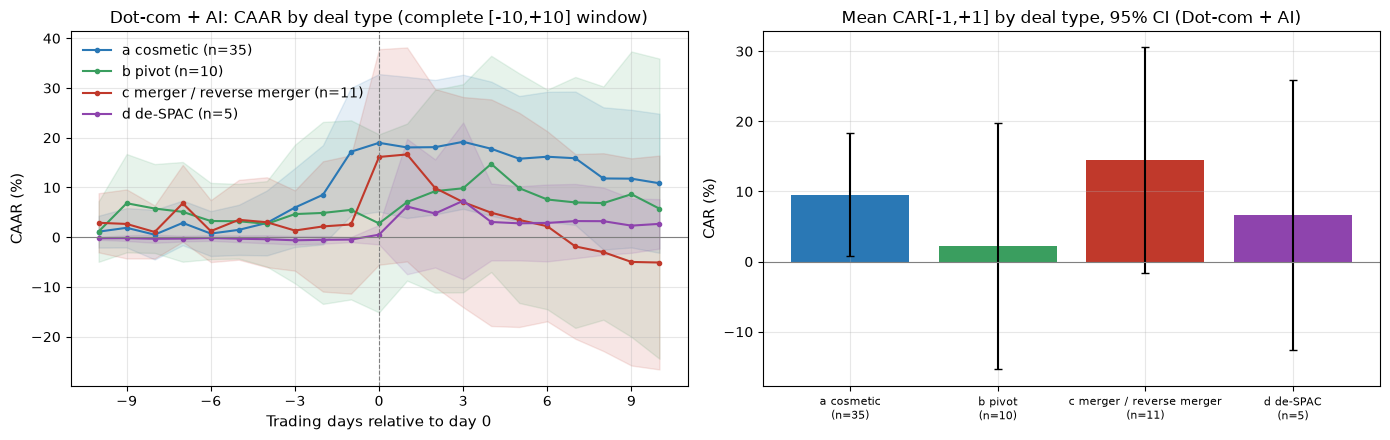

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
pooled = graded[graded["theme"].isin(["Dot-com", "AI"])]
es.plot_caar(abnormal, pooled, "deal_label", deal_colors, axes[0],
             title="Dot-com + AI: CAAR by deal type (complete [-10,+10] window)")
summary = by_deal_type[(by_deal_type["wave"] == "Dot-com + AI") & (by_deal_type["measure"] == es.PRIMARY_MEASURE)
                       & by_deal_type["deal_type"].isin(deal_type_labels.values())]
axes[1].bar(summary["deal_type"], summary["mean"] * 100, color=[deal_colors[d] for d in summary["deal_type"]])
axes[1].errorbar(summary["deal_type"], summary["mean"] * 100,
                 yerr=[(summary["mean"] - summary["ci_low"]) * 100, (summary["ci_high"] - summary["mean"]) * 100],
                 fmt="none", color="black", capsize=3)
axes[1].set_xticks(range(len(summary)), [f"{d}\n(n={int(n)})" for d, n in zip(summary["deal_type"], summary["n"])],
                   fontsize=8)                     # sample size in the tick label, not on the bars
axes[1].axhline(0, color="grey", lw=0.8)
axes[1].set(title="Mean CAR[-1,+1] by deal type, 95% CI (Dot-com + AI)", ylabel="CAR (%)")
axes[1].grid(alpha=0.3)
fig.tight_layout()
fig.savefig(output_dir / "conf_deal_types.png", dpi=150)
plt.show()

In [15]:
with pd.ExcelWriter(output_dir / "confounding_sensitivity_results.xlsx") as writer:
    by_deal_type.to_excel(writer, sheet_name="by_deal_type", index=False)
    sensitivity.to_excel(writer, sheet_name="sensitivity", index=False)
    peak_prevalence.to_excel(writer, sheet_name="peak_years_prevalence", index=False)
    peak_control.to_excel(writer, sheet_name="peak_years_control_group", index=False)
    dictionary_audit.to_excel(writer, sheet_name="dictionary_audit", index=False)
    cars.to_excel(writer, sheet_name="event_level", index=False)
print("results written to", output_dir / "confounding_sensitivity_results.xlsx")

results written to /Users/chunhanliao/Documents/FS_MADS/1_IntroDA/Group Project/IDA_Group7_whats_in_a_buzzword_submission/output/confounding_sensitivity_results.xlsx


## Step 9: Overview figures
A sample-construction diagram and a results-at-a-glance chart that summarise notebooks 02–07 for a first-time
reader. Both are drawn from the saved result tables.

**Sample construction and firms per research question.** Each buzzword rename belongs to a different firm, so
events and firms are the same count.

| Step / question | Firms | Note |
|---|---|---|
| 3 Buzzword in the new name | 97 | Dot-com 79, AI 14, Blockchain 4 (1990–2025) |
| 4 Inside the wave years | 79 | Dot-com 63, AI 14, Blockchain 2 |
| 5 Verified public announcement date (grade A/B) | 65 | |
| 6 No bundled deal (cosmetic rename or pivot) | 49 | the primary sample |
| 7 Complete stock-price window around the announcement | 47 | 2 firms dropped (below) |
| **RQ1** Prevalence | 79 | in wave years (97 over all years), relative to all listed firms |
| **RQ2** Announcement reaction | 47 | Dot-com 37, AI 8, Blockchain 2 (case studies) |
| **RQ3** AI vs Dot-com | 45 | AI 8 vs Dot-com 37 |
| **RQ4** Who rebrands | 79 / 59 | industry for all 79; size, ROA etc. for the 59 with accounts public before the event (Dot-com 51, AI 6, Blockchain 2) |

**Why 49 → 47.** Two primary-sample firms had no exchange prices around their announcement, so no abnormal
return can be measured: **eMusic.com** (formerly GoodNoise; announced 2 June 1999, its first trading day in CRSP)
has no earlier prices for day −1 or the estimation window, and **GlobalMedia.com** (announced 7 March 2000) first
trades in CRSP on 25 April 2000. Both were most likely traded over the counter before their Nasdaq listing.

RQ1 and RQ4 describe all in-wave rebranding firms (track A); RQ2 and RQ3 need a clean, dated announcement and
stock prices around it (track B).

primary-sample events without stock prices around the announcement: ['EMUSIC COM INC', 'GLOBALMEDIA COM']


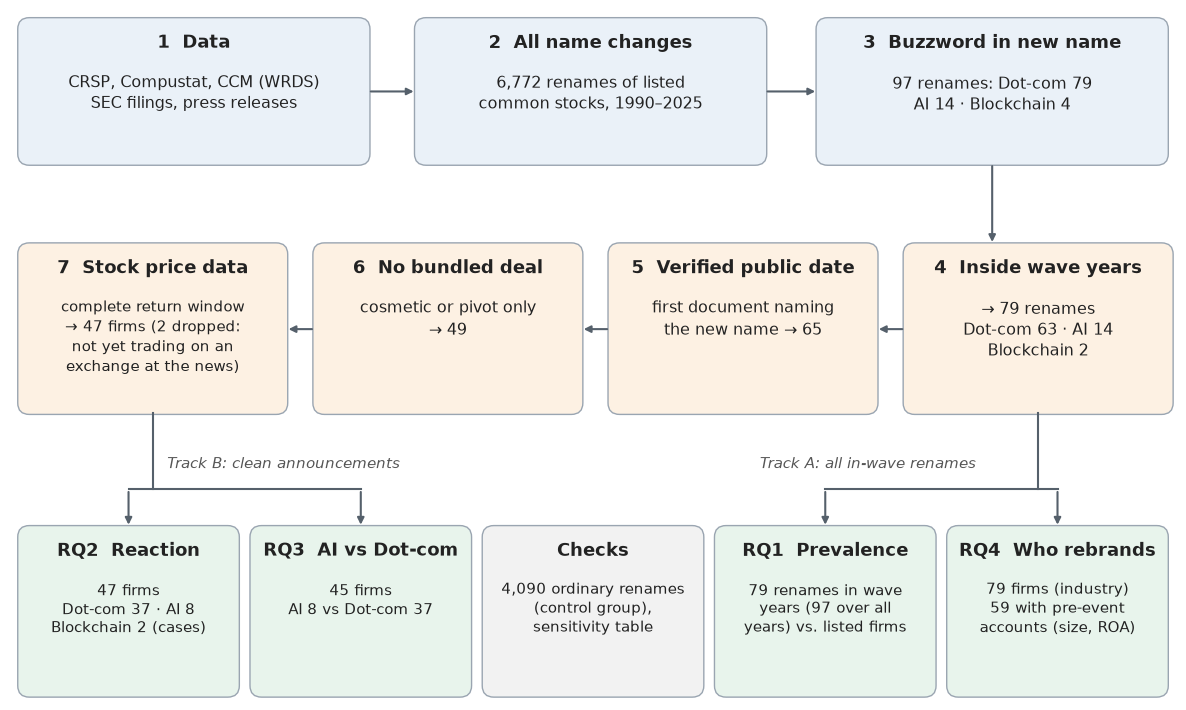

In [16]:
from matplotlib.patches import FancyBboxPatch

ink, muted = "#222222", "#555555"
register = pd.read_excel(base_dir / "event_dates" / "event_register.xlsx", sheet_name="sample_flow")
counts = register.set_index("step")["total"].tolist()                     # 97, 79, grade A/B, deal type a/b
event_level = pd.read_excel(output_dir / "core_analysis_results.xlsx", sheet_name="A_event_level")
in_wave = event_level[event_level["in_wave_period"] == 1]
primary = event_level[event_level["primary_sample"] == 1]
with_car = primary[primary["car_m1_p1"].notna()]                        # complete [-1,+1] window (RQ2)
no_prices = primary[primary["car_m1_p1"].isna()]
n_car = with_car["theme"].value_counts().reindex(themes, fill_value=0)
n_wave = in_wave["theme"].value_counts().reindex(themes, fill_value=0)
n_accounts = in_wave["log_assets"].notna().sum()                         # RQ4 characteristics (pre-event accounts)
n_controls = int(pd.read_excel(output_dir / "control_group_results.xlsx", sheet_name="control_funnel")["total"].iloc[-1])
print("primary-sample events without stock prices around the announcement:", no_prices["new_name"].tolist())


def draw_box(ax, x, y, w, h, title, body, fill, body_size=11.5):
    """
    Draw one rounded box with a bold title and a body text.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
    x, y, w, h : float
        Position and size in axis units.
    title, body : str
    fill : str
        Face colour.
    body_size : float
        Font size of the body text.
    """
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12", fc=fill, ec="#9aa5b1", lw=1))
    ax.text(x + w / 2, y + h - 0.15, title, ha="center", va="top", fontsize=13, weight="bold", color=ink)
    ax.text(x + w / 2, y + h - 0.55, body, ha="center", va="top", fontsize=body_size, color=ink, linespacing=1.3)


def draw_arrow(ax, x1, y1, x2, y2):
    """
    Draw an arrow between two points.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
    x1, y1, x2, y2 : float
    """
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", color="#55606b", lw=1.5))


def draw_branch(ax, x_from, y_from, x_targets, y_split, y_to, label, label_x):
    """
    Draw a line down from one box that splits into arrows to several boxes, with a track label.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
    x_from, y_from : float
        Bottom centre of the source box.
    x_targets : list of float
        Top centres of the target boxes.
    y_split, y_to : float
        Height of the horizontal split line and of the target box tops.
    label : str
    label_x : float
        Left end of the track label.
    """
    ax.plot([x_from, x_from], [y_from, y_split], color="#55606b", lw=1.5)
    ax.plot([min(x_targets), max(x_targets)], [y_split, y_split], color="#55606b", lw=1.5)
    for x in x_targets:
        draw_arrow(ax, x, y_split, x, y_to)
    ax.text(label_x, y_split + 0.22, label, ha="left", fontsize=11, color=muted, style="italic")


n_changes = len(pd.read_csv(processed_dir / "all_name_changes.csv"))
by_theme = events["theme"].value_counts()
fig, ax = plt.subplots(figsize=(12, 7.2))
ax.set_xlim(0, 12.05)
ax.set_ylim(0, 7.2)
ax.axis("off")
row1, row2, row3, w2, w3 = 5.6, 3.0, 0.05, 2.75, 2.25
draw_box(ax, 0.1, row1, 3.6, 1.5, "1  Data", "CRSP, Compustat, CCM (WRDS)\nSEC filings, press releases", "#eaf1f8")
draw_box(ax, 4.2, row1, 3.6, 1.5, "2  All name changes", f"{n_changes:,} renames of listed\ncommon stocks, 1990–2025", "#eaf1f8")
draw_box(ax, 8.35, row1, 3.6, 1.5, "3  Buzzword in new name",
         f"{counts[0]} renames: Dot-com {by_theme['Dot-com']}\nAI {by_theme['AI']} · Blockchain {by_theme['Blockchain']}", "#eaf1f8")
draw_arrow(ax, 3.7, row1 + 0.75, 4.2, row1 + 0.75)
draw_arrow(ax, 7.8, row1 + 0.75, 8.35, row1 + 0.75)
x4, x5, x6, x7 = 9.25, 6.2, 3.15, 0.1                                     # second row runs right to left
draw_box(ax, x4, row2, w2, 1.75, "4  Inside wave years",
         f"→ {counts[1]} renames\nDot-com {n_wave['Dot-com']} · AI {n_wave['AI']}\nBlockchain {n_wave['Blockchain']}", "#fdf1e3")
draw_box(ax, x5, row2, w2, 1.75, "5  Verified public date", f"first document naming\nthe new name → {counts[2]}", "#fdf1e3")
draw_box(ax, x6, row2, w2, 1.75, "6  No bundled deal", f"cosmetic or pivot only\n→ {counts[3]}", "#fdf1e3")
draw_box(ax, x7, row2, w2, 1.75, "7  Stock price data",
         f"complete return window\n→ {len(with_car)} firms ({len(no_prices)} dropped:\nnot yet trading on an\nexchange at the news)",
         "#fdf1e3", body_size=11)
draw_arrow(ax, 10.15, row1, 10.15, row2 + 1.75)
for x_right, x_left in [(x4, x5 + w2), (x5, x6 + w2), (x6, x7 + w2)]:
    draw_arrow(ax, x_right, row2 + 0.87, x_left, row2 + 0.87)
xs = [0.1 + i * 2.4 for i in range(5)]                                    # RQ2, RQ3, checks, RQ1, RQ4
centres = [x + w3 / 2 for x in xs]
draw_box(ax, xs[0], row3, w3, 1.75, "RQ2  Reaction",
         f"{len(with_car)} firms\nDot-com {n_car['Dot-com']} · AI {n_car['AI']}\nBlockchain {n_car['Blockchain']} (cases)",
         "#e8f4ec", body_size=10.5)
draw_box(ax, xs[1], row3, w3, 1.75, "RQ3  AI vs Dot-com",
         f"{n_car['AI'] + n_car['Dot-com']} firms\nAI {n_car['AI']} vs Dot-com {n_car['Dot-com']}", "#e8f4ec", body_size=10.5)
draw_box(ax, xs[2], row3, w3, 1.75, "Checks",
         f"{n_controls:,} ordinary renames\n(control group),\nsensitivity table", "#f2f2f2", body_size=10.5)
draw_box(ax, xs[3], row3, w3, 1.75, "RQ1  Prevalence",
         f"{counts[1]} renames in wave\nyears ({counts[0]} over all\nyears) vs. listed firms", "#e8f4ec", body_size=10.5)
draw_box(ax, xs[4], row3, w3, 1.75, "RQ4  Who rebrands",
         f"{counts[1]} firms (industry)\n{n_accounts} with pre-event\naccounts (size, ROA)", "#e8f4ec", body_size=10.5)
draw_branch(ax, x7 + w2 / 2, row2, centres[:2], 2.2, row3 + 1.75, "Track B: clean announcements", x7 + w2 / 2 + 0.15)
draw_branch(ax, x4 + w2 / 2, row2, centres[3:], 2.2, row3 + 1.75, "Track A: all in-wave renames", 7.75)
fig.tight_layout()
fig.savefig(output_dir / "overview_pipeline.png", dpi=170)
plt.show()

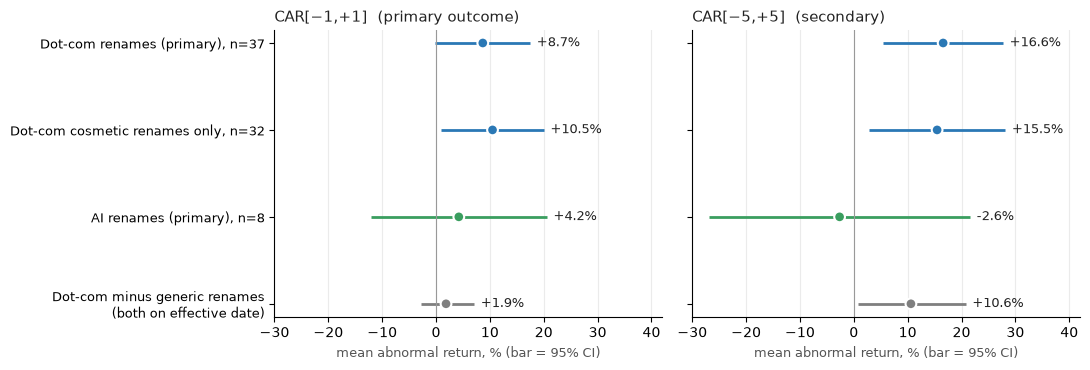

,label,measure,mean,low,high
0,"Dot-com renames (primary), n=37",car_m1_p1,0.0869,-0.0014,0.1751
1,"AI renames (primary), n=8",car_m1_p1,0.0423,-0.1215,0.2061
2,"Dot-com cosmetic renames only, n=32",car_m1_p1,0.1049,0.0094,0.2005
3,Dot-com minus generic renames\n(both on effect...,car_m1_p1,0.0186,-0.0273,0.0712
4,"Dot-com renames (primary), n=37",car_m5_p5,0.1659,0.0545,0.2774
5,"AI renames (primary), n=8",car_m5_p5,-0.0264,-0.2690,0.2163
6,"Dot-com cosmetic renames only, n=32",car_m5_p5,0.1547,0.0278,0.2816
7,Dot-com minus generic renames\n(both on effect...,car_m5_p5,0.1061,0.0086,0.2081


In [17]:
core = pd.read_excel(output_dir / "core_analysis_results.xlsx", sheet_name="rq2_event_study")
control = pd.read_excel(output_dir / "control_group_results.xlsx", sheet_name="thematic_minus_control")
rows = []
for measure in [es.PRIMARY_MEASURE, "car_m5_p5"]:
    for label, table, sample, color in [("Dot-com renames (primary)", core, "Dot-com (primary)", theme_colors["Dot-com"]),
                                        ("AI renames (primary)", core, "AI (primary)", theme_colors["AI"])]:
        r = table[(table["sample"] == sample) & (table["measure"] == measure)].iloc[0]
        rows.append((f"{label}, n={int(r['n'])}", measure, r["mean"], r["ci_low"], r["ci_high"], color))
    r = by_deal_type[(by_deal_type["wave"] == "Dot-com") & (by_deal_type["deal_type"] == "a cosmetic")
                     & (by_deal_type["measure"] == measure)].iloc[0]
    rows.append((f"Dot-com cosmetic renames only, n={int(r['n'])}", measure, r["mean"], r["ci_low"], r["ci_high"],
                 theme_colors["Dot-com"]))
    r = control[control["specification"].str.startswith("A:") & (control["wave"] == "Dot-com")
                & (control["outcome"] == measure)].iloc[0]
    rows.append(("Dot-com minus generic renames\n(both on effective date)", measure, r["difference"], r["boot_ci_low"],
                 r["boot_ci_high"], "#7f7f7f"))
glance = pd.DataFrame(rows, columns=["label", "measure", "mean", "low", "high", "color"])
order = [glance["label"].iloc[i] for i in (0, 2, 1, 3)][::-1]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, measure, title in zip(axes, [es.PRIMARY_MEASURE, "car_m5_p5"],
                              ["CAR[−1,+1]  (primary outcome)", "CAR[−5,+5]  (secondary)"]):
    d = glance[glance["measure"] == measure].set_index("label").loc[order]
    y = range(len(d))
    ax.hlines(y, d["low"] * 100, d["high"] * 100, color=d["color"], lw=2)
    ax.scatter(d["mean"] * 100, y, color=d["color"], s=60, zorder=3, edgecolor="white", linewidth=1.5)
    for yi, (m, high) in enumerate(zip(d["mean"], d["high"])):
        ax.text(high * 100 + 1.2, yi, f"{m * 100:+.1f}%", va="center", fontsize=9, color=ink)
    ax.axvline(0, color="#999999", lw=0.8)
    ax.set_title(title, fontsize=11, color=ink, loc="left")
    ax.set_xlabel("mean abnormal return, % (bar = 95% CI)", color=muted, fontsize=9)
    ax.grid(axis="x", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlim(-30, 42)
axes[0].set_yticks(range(len(order)), order, fontsize=9)
fig.tight_layout()
fig.savefig(output_dir / "overview_results_at_a_glance.png", dpi=170)
plt.show()
glance.drop(columns="color").round(4)

## Summary (numbers from the run above)
**Deal types (in-wave, grade A/B dates).** Dot-com: 32 cosmetic renames, 5 pivots, 10 merger-related renames.
AI: 3 cosmetic, 5 pivots, 1 reverse merger, 5 de-SPAC deal announcements.

**Does the Dot-com reaction survive the de Jong & Naumovska test?** In our sample, yes, at least for the mean:
* **cosmetic Dot-com renames only:** CAR[−1,+1] = **+10.5%** (95% CI +0.9% to +20.0%, bootstrap p = 0.02,
  month-clustered p = 0.008), CAR[−5,+5] +15.5% (p = 0.01). The median (+7.4%) is positive but the sign test is
  not significant (p = 0.22), so a minority of large reactions carries the mean;
* merger-related Dot-com renames: +12.6% (n = 10, p = 0.09), i.e. not larger than the cosmetic renames;
* unlike Cooper, Dimitrov & Rau's (2001) sample, ours is dominated by cosmetic renames (32 of 47), because it is
  restricted to exchange-listed stocks; de Jong & Naumovska's confounders (reverse mergers of OTC shells) are rare.

**AI.** No deal type shows a significant reaction (all n ≤ 5). AI de-SPAC **deal announcements** earn +6.7% on
average; the large losses seen in notebook 05 happen at the **closing** (effective date), not at the announcement.

**Sensitivity of the primary Dot-com CAR[−1,+1] (+8.7%).** The estimate stays between +7% and +12% when the
sample uses grade A dates only (+12.3%), cosmetic renames only (+10.5%), all deal types (+9.5%), excludes the
second-check rows (+10.3%), adds events outside the wave (+7.3%), adds grade-C events (+9.5%), uses the earliest of all
recorded dates (+8.6%), a market-adjusted benchmark (+9.1%) or the strict ≥ 60-day sample (+8.5%). It **disappears** when day 0
moves one session later (+1.2%) or to the CRSP effective date (−0.3%), and it falls to +6.4% (p = 0.09) without
the single most influential event. The wider window CAR[−5,+5] is positive and significant in every specification
except the effective-date one (+9.7%, p = 0.09).

**Reading.** The Dot-com reaction is concentrated on the announcement days, is not explained by bundled mergers,
and does not hinge on the choice of event date; but it rests on the mean of a skewed distribution, so the evidence is
moderate (and not significant after the Holm correction in notebook 03). Nothing can be concluded for AI.

**Peak-years check (wave windows).** 36 of 37 primary Dot-com events and all 8 AI events fall in the
literature-based peak years, so the reaction results are unchanged (Dot-com CAR[−1,+1] +8.7%, p = 0.05;
CAR[−5,+5] +17.0%, p = 0.002). The control-group premium also holds in the peak years (Dot-com CAR[−5,+5]
+12.2 pp, p = 0.02). Only the RQ1 **averages** change, because quiet years drop out: Dot-com 2.5 renames per 1,000
listed firms per year in 1998–2000 (0.98 over 1995–2002), AI 0.80 in 2023–2025 (0.52), Blockchain 0.22 in
2017–2018 (0.09); the ranking of the waves is the same. Conclusion: the exact wave boundaries do not drive the
results.

**Threshold check.** Allowing a first trade up to 5 sessions after day 0, requiring 40 baseline days, or requiring
120 estimation days for the market model changes no primary event: the results are identical.

**Dictionary audit (light).** 55 other name changes introduce one of the excluded ambiguous words. 11 of them are
buzzword renames the dictionary misses, mostly **crypto miners named "… Digital"** (Bit Digital, Marathon Digital,
BTC Digital). Inside the wave years this adds 1 Dot-com rename (J Net Enterprises, 2001: 63 → 64), 2 Blockchain
renames (Bit Digital and Code Chain New Continent, 2020: 2 → 4) and 1 borderline AI rename (Near Intelligence,
2023: 14 → 15). Dot-com and AI counts are robust; the Blockchain count is a **lower bound**, which reinforces the
finding that listed Blockchain renames are rare but understates them. The missed renames are not added to the
return analysis (no verified announcement dates).